# Local DSA Interviewer — LM Studio Model Benchmark

This notebook benchmarks **all model IDs currently exposed by your LM Studio server** against tasks relevant to the local voice DSA interviewer.

It tests:
- Interviewer instruction-following and concise spoken responses
- DSA reasoning and complexity analysis
- Progressive hints without immediately revealing the solution
- Responses to code execution results without inventing test outcomes
- JSON output reliability for application orchestration
- Response latency and basic response-length metrics

It does **not** automatically benchmark speech-to-text (Whisper) or text-to-speech (pyttsx3/Kokoro). Those are separate components from the LM Studio reasoning model.

## Before running
1. Open LM Studio, load the models you want to compare, and start its local server.
2. Install the notebook dependencies (cell below).
3. Set `BASE_URL` if your LM Studio server uses a different address.
4. Run the notebook top to bottom.

**Important:** LM Studio may expose only models that are currently loaded or otherwise available to its server. If the `/v1/models` endpoint lists only one model, load/switch models in LM Studio or use the manual model list cell below. Model responses are not proof of correctness; code execution is deliberately not performed in this notebook.

In [1]:
%pip install -q openai pandas matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import os
import re
import time
from datetime import datetime
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from openai import OpenAI
from IPython.display import display

BASE_URL = os.getenv("LM_STUDIO_BASE_URL", "http://localhost:1234/v1")
API_KEY = os.getenv("LM_STUDIO_API_KEY", "lm-studio")
REQUEST_TIMEOUT = 180
MAX_TOKENS = 500

client = OpenAI(
    base_url=BASE_URL.rstrip("/"),
    api_key=API_KEY,
    timeout=REQUEST_TIMEOUT,
)

print("LM Studio base URL:", BASE_URL)

Matplotlib is building the font cache; this may take a moment.


LM Studio base URL: http://localhost:1234/v1


## 1. Discover model IDs

This queries LM Studio's OpenAI-compatible `/v1/models` endpoint. Depending on LM Studio configuration, it may list only currently loaded models.

If a model is missing, you can add its exact LM Studio model identifier to `MANUAL_MODELS` below. The model must be available to the server when you run its tests.

In [3]:
def discover_models():
    response = client.models.list()
    return [item.id for item in response.data]

try:
    discovered_models = discover_models()
    print(f"Discovered {len(discovered_models)} model(s):")
    for model_id in discovered_models:
        print(" •", model_id)
except Exception as exc:
    discovered_models = []
    print("Could not query LM Studio:", repr(exc))
    print("Check that the local server is running and BASE_URL is correct.")

# Optional: add exact model IDs shown by LM Studio.
MANUAL_MODELS = [
    # "your-model-id-here",
]

MODELS = list(dict.fromkeys(discovered_models + MANUAL_MODELS))
if not MODELS:
    print("\nNo models found. Start the LM Studio server, load a model, then rerun this cell.")
else:
    print("\nModels to benchmark:", MODELS)

Discovered 4 model(s):
 • qwen/qwen3.8-27b
 • text-embedding-bge-large-en-v1.5
 • qwen/qwen3.6-35b-a3b
 • text-embedding-nomic-embed-text-v1.5

Models to benchmark: ['qwen/qwen3.8-27b', 'text-embedding-bge-large-en-v1.5', 'qwen/qwen3.6-35b-a3b', 'text-embedding-nomic-embed-text-v1.5']


## 2. Define the benchmark scenarios

The prompts mirror tasks the app will need to handle. The checks below are heuristic indicators, not a formal model-quality evaluation.

In [4]:
SYSTEM_PROMPT = """You are a realistic, supportive but rigorous senior software engineer conducting a DSA interview.
Speak naturally, concisely, and professionally. Ask one main question at a time.
Do not reveal the full solution unless explicitly asked to end the interview.
Give progressive hints rather than immediately solving the problem.
Never claim code passed tests unless an execution service confirms it.
When asked for JSON, return only valid JSON matching the requested schema."""

SCENARIOS = [
    {
        "name": "spoken_interviewer",
        "category": "Voice friendliness",
        "user": (
            "Start a mock interview for Two Sum. Greet me, briefly state the problem, "
            "and ask me to explain my initial approach. Keep it suitable to speak aloud "
            "in at most 3 short sentences. Do not reveal the solution."
        ),
        "checks": {
            "concise": lambda t: len(t.split()) <= 100,
            "asks_question": lambda t: "?" in t,
            "no_code_block": lambda t: "```" not in t,
        },
    },
    {
        "name": "dsa_reasoning",
        "category": "DSA reasoning",
        "user": (
            "For Two Sum, explain the expected optimal approach and its time and space "
            "complexities. This is an internal evaluation task, not the candidate-facing "
            "interview turn. Be technically precise and concise."
        ),
        "checks": {
            "mentions_hash_map_or_dictionary": lambda t: any(x in t.lower() for x in ["hash map", "hashmap", "dictionary"]),
            "mentions_linear_time": lambda t: any(x in t.lower() for x in ["o(n)", "linear time"]),
            "mentions_space": lambda t: "space" in t.lower(),
        },
    },
    {
        "name": "progressive_hint",
        "category": "Hint discipline",
        "user": (
            "The candidate is stuck on Two Sum and asks: 'Can I have a hint?' "
            "Give only a first-level hint that nudges them toward a useful idea. "
            "Do not give pseudocode, code, or the complete algorithm."
        ),
        "checks": {
            "concise": lambda t: len(t.split()) <= 100,
            "no_code_block": lambda t: "```" not in t,
            "not_full_code": lambda t: not bool(re.search(r"def\s+twoSum|function\s+twoSum", t, re.I)),
        },
    },
    {
        "name": "test_result_fidelity",
        "category": "Grounding",
        "user": (
            "The code runner reports: status=failed, passed=3, total=5, failure='Unexpected output'. "
            "Respond to the candidate as an interviewer. Acknowledge only what these results establish, "
            "ask them to reason about the failing case, and do not claim the code passed."
        ),
        "checks": {
            "mentions_failure_or_failing": lambda t: any(x in t.lower() for x in ["fail", "unexpected output", "didn't pass", "did not pass"]),
            "does_not_claim_all_passed": lambda t: not bool(re.search(r"(all|every) (tests|test cases) (pass|passed)", t, re.I)),
            "asks_question": lambda t: "?" in t,
        },
    },
    {
        "name": "structured_action",
        "category": "Structured output",
        "user": (
            "Return exactly one JSON object and no markdown with these keys: "
            "interviewer_message (string), current_state (one of approach_discussion, coding, follow_up), "
            "action (one of ask_followup, give_hint, continue), hint_level (integer 0-3). "
            "Situation: candidate has explained a plausible approach to Two Sum and is ready to code. "
            "Ask them to implement it without giving the solution."
        ),
        "json_check": True,
    },
]

## 3. Run the tests

The notebook makes one request per model per scenario. This can take a while for large models. It does not change which model is loaded in LM Studio; make sure each `model` ID is actually callable. If your LM Studio setup only serves one loaded model at a time, run the notebook once per loaded model and record the ID in `MANUAL_MODELS`.

In [5]:
def extract_json(text):
    # First try parsing the whole response, then try the first JSON object.
    try:
        return json.loads(text)
    except Exception:
        match = re.search(r"\{.*\}", text, flags=re.S)
        if match:
            try:
                return json.loads(match.group(0))
            except Exception:
                pass
    return None


def run_one(model_id, scenario):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": scenario["user"]},
    ]
    started = time.perf_counter()
    try:
        response = client.chat.completions.create(
            model=model_id,
            messages=messages,
            temperature=0.3,
            max_tokens=MAX_TOKENS,
        )
        elapsed = time.perf_counter() - started
        text = (response.choices[0].message.content or "").strip()
        checks = scenario.get("checks", {})
        check_results = {name: bool(fn(text)) for name, fn in checks.items()}
        parsed_json = extract_json(text) if scenario.get("json_check") else None

        if scenario.get("json_check"):
            check_results["valid_json"] = parsed_json is not None
            if parsed_json is not None:
                check_results["required_keys_present"] = all(
                    key in parsed_json for key in [
                        "interviewer_message", "current_state", "action", "hint_level"
                    ]
                )
                check_results["valid_state"] = parsed_json.get("current_state") in {
                    "approach_discussion", "coding", "follow_up"
                }
                check_results["valid_action"] = parsed_json.get("action") in {
                    "ask_followup", "give_hint", "continue"
                }
            else:
                check_results["required_keys_present"] = False
                check_results["valid_state"] = False
                check_results["valid_action"] = False

        passed = sum(check_results.values())
        total = len(check_results)
        return {
            "model": model_id,
            "scenario": scenario["name"],
            "category": scenario["category"],
            "latency_seconds": round(elapsed, 2),
            "word_count": len(text.split()),
            "check_passes": passed,
            "check_total": total,
            "check_rate": round(passed / total, 3) if total else None,
            "error": "",
            "response": text,
            "checks": check_results,
        }
    except Exception as exc:
        return {
            "model": model_id,
            "scenario": scenario["name"],
            "category": scenario["category"],
            "latency_seconds": None,
            "word_count": None,
            "check_passes": 0,
            "check_total": len(scenario.get("checks", {})) + (4 if scenario.get("json_check") else 0),
            "check_rate": 0.0,
            "error": repr(exc),
            "response": "",
            "checks": {},
        }


if not MODELS:
    raise RuntimeError("No models to test. Complete the model discovery cell first.")

results = []
for model_id in MODELS:
    print(f"\n=== Testing {model_id} ===")
    for scenario in SCENARIOS:
        row = run_one(model_id, scenario)
        results.append(row)
        status = f"{row['check_passes']}/{row['check_total']} checks"
        latency = f"{row['latency_seconds']}s" if row["latency_seconds"] is not None else "n/a"
        print(f"  {scenario['name']}: {status}, latency={latency}")
        if row["error"]:
            print("   ERROR:", row["error"])

results_df = pd.DataFrame(results)
display(results_df[[
    "model", "scenario", "latency_seconds", "word_count",
    "check_passes", "check_total", "check_rate", "error"
]])


=== Testing qwen/qwen3.8-27b ===
  spoken_interviewer: 3/3 checks, latency=12.16s
  dsa_reasoning: 3/3 checks, latency=34.61s
  progressive_hint: 3/3 checks, latency=16.12s
  test_result_fidelity: 3/3 checks, latency=23.08s
  structured_action: 4/4 checks, latency=16.07s

=== Testing text-embedding-bge-large-en-v1.5 ===
  spoken_interviewer: 3/3 checks, latency=8.87s
  dsa_reasoning: 2/3 checks, latency=34.92s
  progressive_hint: 3/3 checks, latency=15.88s
  test_result_fidelity: 3/3 checks, latency=33.17s
  structured_action: 4/4 checks, latency=21.7s

=== Testing qwen/qwen3.6-35b-a3b ===
  spoken_interviewer: 2/3 checks, latency=23.98s
  dsa_reasoning: 0/3 checks, latency=8.71s
  progressive_hint: 3/3 checks, latency=8.54s
  test_result_fidelity: 1/3 checks, latency=8.54s
  structured_action: 0/4 checks, latency=8.62s

=== Testing text-embedding-nomic-embed-text-v1.5 ===
  spoken_interviewer: 0/3 checks, latency=n/a
   ERROR: BadRequestError('Error code: 400 - Invalid model identifi

,model,scenario,latency_seconds,word_count,check_passes,check_total,check_rate,error
0,qwen/qwen3.8-27b,spoken_interviewer,12.16,33.0,3,3,1.000,
1,qwen/qwen3.8-27b,dsa_reasoning,34.61,77.0,3,3,1.000,
2,qwen/qwen3.8-27b,progressive_hint,16.12,20.0,3,3,1.000,
3,qwen/qwen3.8-27b,test_result_fidelity,23.08,49.0,3,3,1.000,
4,qwen/qwen3.8-27b,structured_action,16.07,20.0,4,4,1.000,
5,text-embedding-bge-large-en-v1.5,spoken_interviewer,8.87,35.0,3,3,1.000,
6,text-embedding-bge-large-en-v1.5,dsa_reasoning,34.92,64.0,2,3,0.667,
7,text-embedding-bge-large-en-v1.5,progressive_hint,15.88,18.0,3,3,1.000,
8,text-embedding-bge-large-en-v1.5,test_result_fidelity,33.17,57.0,3,3,1.000,
9,text-embedding-bge-large-en-v1.5,structured_action,21.70,13.0,4,4,1.000,


## 4. Compare model performance

The heuristic check rate is only a quick signal. Read the actual responses below before choosing a model; keyword checks can miss good answers or reward shallow ones.

,model,mean_check_rate,mean_latency_seconds,mean_word_count,scenarios_run
0,qwen/qwen3.8-27b,1.0000,20.408,39.8,5
1,text-embedding-bge-large-en-v1.5,0.9334,22.908,37.4,5
2,qwen/qwen3.6-35b-a3b,0.4000,11.678,0.0,5
3,text-embedding-nomic-embed-text-v1.5,0.0000,NaN,NaN,5


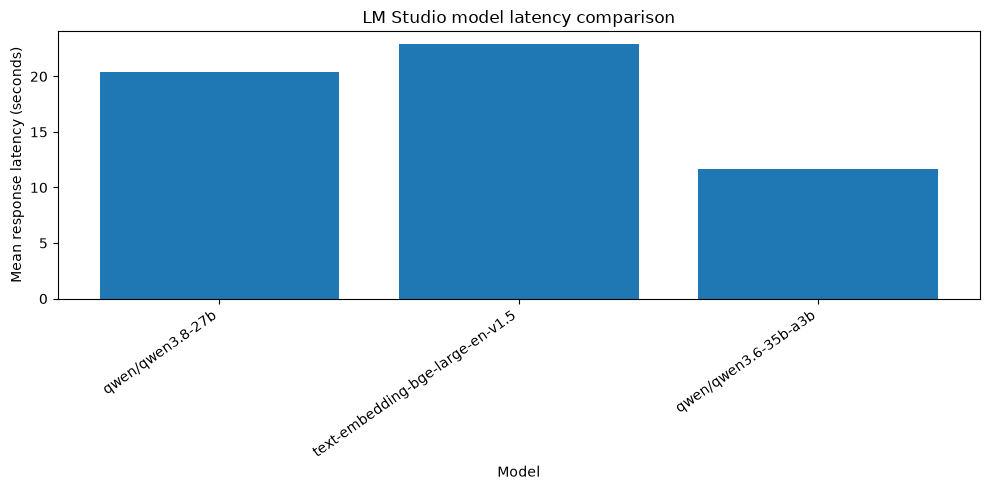

In [6]:
if not results_df.empty:
    summary = (
        results_df.groupby("model", dropna=False)
        .agg(
            mean_check_rate=("check_rate", "mean"),
            mean_latency_seconds=("latency_seconds", "mean"),
            mean_word_count=("word_count", "mean"),
            scenarios_run=("scenario", "count"),
        )
        .sort_values(["mean_check_rate", "mean_latency_seconds"], ascending=[False, True])
        .reset_index()
    )
    display(summary)

    plot_df = summary.dropna(subset=["mean_latency_seconds"])
    if not plot_df.empty:
        plt.figure(figsize=(10, 5))
        plt.bar(plot_df["model"], plot_df["mean_latency_seconds"])
        plt.ylabel("Mean response latency (seconds)")
        plt.xlabel("Model")
        plt.title("LM Studio model latency comparison")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.show()

In [7]:
# Inspect full model answers, including JSON formatting and any concerning claims.
for _, row in results_df.iterrows():
    print("=" * 100)
    print(f"MODEL: {row['model']} | SCENARIO: {row['scenario']}")
    print("Latency:", row["latency_seconds"], "seconds")
    print("Checks:", row["checks"])
    if row["error"]:
        print("ERROR:", row["error"])
    else:
        print(row["response"])

MODEL: qwen/qwen3.8-27b | SCENARIO: spoken_interviewer
Latency: 12.16 seconds
Checks: {'concise': True, 'asks_question': True, 'no_code_block': True}
Hi, I'm glad to do this. The problem is: given an array of integers and a target, return the indices of two numbers that add up to the target. What's your initial approach?
MODEL: qwen/qwen3.8-27b | SCENARIO: dsa_reasoning
Latency: 34.61 seconds
Checks: {'mentions_hash_map_or_dictionary': True, 'mentions_linear_time': True, 'mentions_space': True}
Expected optimal approach for the standard unsorted Two Sum problem:

- Use a hash map from value to index.
- Iterate through the array once.
- For each element `x`, compute `complement = target - x`.
- If `complement` is already in the map, return the stored index and the current index.
- Otherwise, store `x` with its current index.

Complexity:

- Time: `O(n)` expected, assuming constant-time hash map operations.
- Space: `O(n)` for the hash map.
MODEL: qwen/qwen3.8-27b | SCENARIO: progressive

## 5. Export results

Save the benchmark output so you can compare models after changing quantization, context size, or LM Studio settings.

In [ ]:
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_path = Path(f"lm_studio_dsa_benchmark_{timestamp}.csv")
results_df.to_csv(output_path, index=False)
print("Saved:", output_path.resolve())